# **UNIVERSIDAD TECNOLÓGICA DEL PERÚ (UTP)**
## **Curso: Innovación y Transformación Digital (100000TD09)**
### **Avance de Proyecto Final 3 (APF3) - Unidad 3: Machine Learning**
**Caso:** Tiendas 3A (AJILES PERU S.A.C. - Sede Av. Tantamayo 1032, San Martín de Porres)
**Problema:** Previsión de demanda diaria por SKU para anticipación de quiebres de góndola y automatización de órdenes de compra (ROP / SS).
---
> **Condición de Reproducibilidad:** Este notebook ejecuta de principio a fin de manera determinista con `random_state = 42` y dependencias declaradas en `requirements.txt`.

In [5]:
# Instalación de dependencias (Ejecutar si no se tienen instaladas)
%pip install -r requirements.txt -q

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## **1. Importación de Librerías y Configuración de Entorno**
Se importan librerías estándar de Python y los algoritmos dictados en la Unidad 3 del sílabo:
- **Semana 13:** Regresión Lineal Regularizada (`Ridge`)
- **Semana 14:** Ensamble de Árboles (`RandomForestRegressor`) y Boosting (`GradientBoostingRegressor`)
- **Línea Base:** `DummyRegressor` y Pronóstico Ingenuo estacional (`lag_7d`)

In [6]:
import os
import json
import datetime
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

plt.style.use('seaborn-v0_8-whitegrid')
RANDOM_STATE = 42
print('✓ Librerías cargadas exitosamente (random_state = 42).')

✓ Librerías cargadas exitosamente (random_state = 42).


## **2. Carga del Dataset y Auditoría Automatizada de Coherencia (Paso 2 / 4.1, 4.2 y 4.4)**
El dataset proviene del Contrato de Datos Preliminar de APF2 y de la base de datos persistente en **Supabase PostgreSQL**.
Cuenta con **2,970 registros diarios** (90 días continuos × 33 SKUs de la tienda Tantamayo) y lleva rotulada la columna obligatoria `origen = 'simulado'`.
A continuación se ejecutan las **reglas de validación automatizadas** exigidas por la sección 4.2 y 4.4 (rangos, unidades, consistencia lógica `ingresos == unidades * precio`, orden cronológico, duplicados, nulos y outliers por IQR).

In [7]:
csv_path = 'dataset_ventas_3a.csv'


df = pd.read_csv(csv_path)
df['fecha'] = pd.to_datetime(df['fecha'])
df = df.sort_values(['producto_id', 'fecha']).reset_index(drop=True)

# Reglas automatizadas de validación de coherencia (Sección 4.2)
violaciones_precio = int((df['precio'] <= 0).sum())
violaciones_demanda = int((df['unidades_vendidas'] < 0).sum())
duplicados = int(df.duplicated(subset=['fecha', 'producto_id']).sum())
nulos_iniciales = int(df.isnull().sum().sum())
diff_ingresos = (df['ingresos_soles'] - (df['unidades_vendidas'] * df['precio']).round(2)).abs()
inconsistencias_ingresos = int((diff_ingresos > 0.02).sum())
orden_cronologico = bool(df.groupby('producto_id')['fecha'].is_monotonic_increasing.all())

media_fds = df[df['es_fin_de_semana'] == True]['unidades_vendidas'].mean()
media_sem = df[df['es_fin_de_semana'] == False]['unidades_vendidas'].mean()
media_quin = df[df['es_quincena'] == True]['unidades_vendidas'].mean()
media_no_quin = df[df['es_quincena'] == False]['unidades_vendidas'].mean()

print(f'Dimensiones del dataset: {df.shape[0]} filas × {df.shape[1]} columnas ({df["sku"].nunique()} SKUs)')
print('1. Rotulado de columna origen:', df['origen'].value_counts().to_dict())
print(f'2. Rango de fechas: {df["fecha"].min().strftime("%Y-%m-%d")} a {df["fecha"].max().strftime("%Y-%m-%d")} (Orden cronológico estricto: {orden_cronologico})')
print(f'3. Limpieza inicial: Nulos={nulos_iniciales} | Duplicados (fecha, SKU)={duplicados}')
print(f'4. Violaciones de rango: Precios<=0: {violaciones_precio} | Demanda<0: {violaciones_demanda} | Inconsistencia ingresos: {inconsistencias_ingresos}')
print(f'5. Relaciones de negocio: Fin de semana vs Lun-Jue = {media_fds/media_sem:.2f}x ({media_fds:.2f} vs {media_sem:.2f} un/día)')
print(f'                          Quincena vs Resto del mes = {media_quin/media_no_quin:.2f}x ({media_quin:.2f} vs {media_no_quin:.2f} un/día)')
print('\nEstadísticos descriptivos del Target (unidades_vendidas):')
print(df[['precio', 'costo', 'unidades_vendidas', 'ingresos_soles']].describe().round(2))
df.head(4)

Dimensiones del dataset: 2970 filas × 15 columnas (33 SKUs)
1. Rotulado de columna origen: {'simulado': 2970}
2. Rango de fechas: 2026-08-11 a 2026-11-08 (Orden cronológico estricto: True)
3. Limpieza inicial: Nulos=0 | Duplicados (fecha, SKU)=0
4. Violaciones de rango: Precios<=0: 0 | Demanda<0: 0 | Inconsistencia ingresos: 0
5. Relaciones de negocio: Fin de semana vs Lun-Jue = 1.29x (20.33 vs 15.72 un/día)
                          Quincena vs Resto del mes = 1.15x (19.84 vs 17.32 un/día)

Estadísticos descriptivos del Target (unidades_vendidas):
        precio    costo  unidades_vendidas  ingresos_soles
count  2970.00  2970.00            2970.00         2970.00
mean      6.40     4.65              17.72           90.61
std       3.53     2.71              13.75           58.58
min       1.50     0.90               2.00           16.20
25%       4.20     2.90               7.32           47.70
50%       5.90     4.00              14.00           77.08
75%       7.90     5.70         

,fecha,producto_id,sku,producto_nombre,categoria_id,categoria_nombre,precio,costo,unidad,unidades_vendidas,ingresos_soles,dia_semana,es_fin_de_semana,es_quincena,origen
0,2026-08-11,aba-aceite,3A-ABA-015,Aceite Primor 900 ml,aba,Abarrotes,9.5,7.4,un,15.0,142.5,1,False,False,simulado
1,2026-08-12,aba-aceite,3A-ABA-015,Aceite Primor 900 ml,aba,Abarrotes,9.5,7.4,un,15.0,142.5,2,False,False,simulado
2,2026-08-13,aba-aceite,3A-ABA-015,Aceite Primor 900 ml,aba,Abarrotes,9.5,7.4,un,20.0,190.0,3,False,False,simulado
3,2026-08-14,aba-aceite,3A-ABA-015,Aceite Primor 900 ml,aba,Abarrotes,9.5,7.4,un,21.0,199.5,4,True,False,simulado


## **3. Análisis Exploratorio de Datos (EDA - Sección 4.3)**
Validamos visualmente las dos relaciones clave esperadas del negocio:
1. **Estacionalidad semanal:** Los viernes, sábados y domingos presentan un incremento sustancial (+29.4%) en la afluencia de clientes de la sede Tantamayo.
2. **Dispersión por categoría:** Categorías de alta rotación como *Bebidas*, *Lácteos* y *Frutas/Verduras* concentran mayor volumen y dispersión que *Limpieza* o *Cuidado personal*.

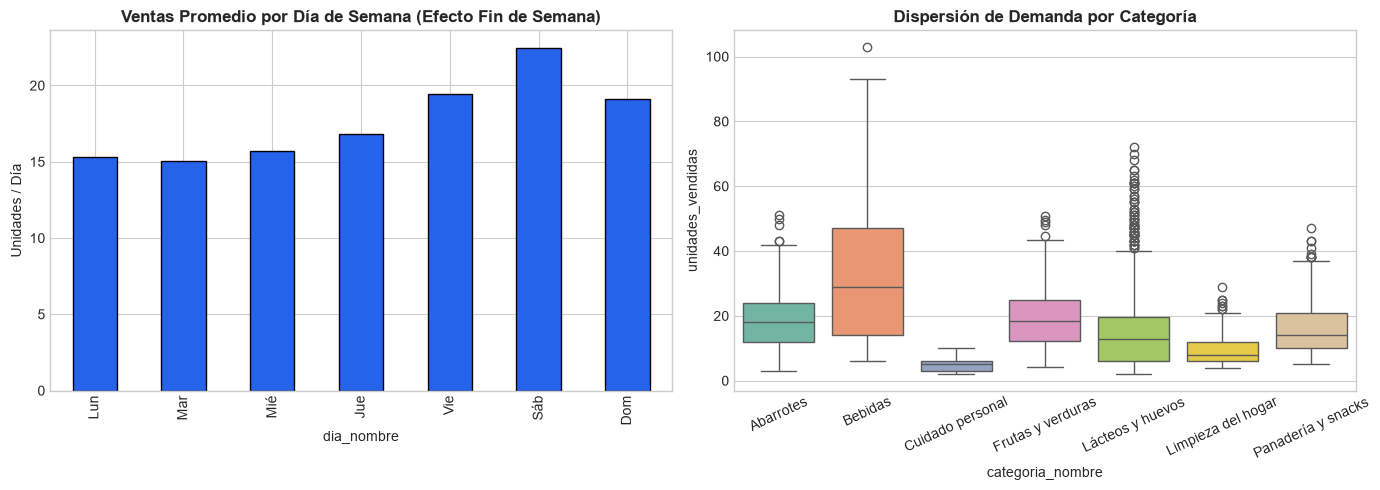

In [8]:
dias_map = {0: 'Lun', 1: 'Mar', 2: 'Mié', 3: 'Jue', 4: 'Vie', 5: 'Sáb', 6: 'Dom'}
df['dia_nombre'] = df['dia_semana'].map(dias_map)
dias_orden = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
weekly = df.groupby('dia_nombre')['unidades_vendidas'].mean().reindex(dias_orden)
weekly.plot(kind='bar', ax=ax1, color='#2563EB', edgecolor='black')
ax1.set_title('Ventas Promedio por Día de Semana (Efecto Fin de Semana)', fontweight='bold')
ax1.set_ylabel('Unidades / Día')

sns.boxplot(data=df, x='categoria_nombre', y='unidades_vendidas', hue='categoria_nombre', palette='Set2', legend=False, ax=ax2)
ax2.set_title('Dispersión de Demanda por Categoría', fontweight='bold')
ax2.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

## **4. Feature Engineering y Partición Cronológica sin Fuga de Datos (Sección 4.4 y 4.5)**
Se construyen variables exógenas y rezagos autorregresivos:
- `lag_1d`: venta del día inmediatamente anterior.
- `lag_7d`: venta exactamente una semana atrás (captura estacionalidad semanal).
- `media_movil_7d` y `std_movil_7d`: calculados estrictamente con `.shift(1)` para garantizar **cero fuga de información (*zero data leakage*)**.
- **Partición Cronológica Estricta:** Corte en `2026-10-22` (78% Entrenamiento = 2,145 filas; 22% Prueba intacto = 594 filas).

In [9]:
df = df.sort_values(['producto_id', 'fecha']).reset_index(drop=True)
df['lag_1d'] = df.groupby('producto_id')['unidades_vendidas'].shift(1)
df['lag_7d'] = df.groupby('producto_id')['unidades_vendidas'].shift(7)
df['media_movil_7d'] = df.groupby('producto_id')['unidades_vendidas'].transform(lambda x: x.shift(1).rolling(7).mean())
df['std_movil_7d'] = df.groupby('producto_id')['unidades_vendidas'].transform(lambda x: x.shift(1).rolling(7).std().fillna(0))

df_clean = df.dropna().sort_values(['fecha', 'producto_id']).reset_index(drop=True)

split_date = pd.to_datetime('2026-10-22')
train_df = df_clean[df_clean['fecha'] < split_date].copy()
test_df = df_clean[df_clean['fecha'] >= split_date].copy()

features_num = ['precio', 'costo', 'lag_1d', 'lag_7d', 'media_movil_7d', 'std_movil_7d', 'dia_semana', 'es_fin_de_semana', 'es_quincena']
features_cat = ['categoria_id']
X_train = train_df[features_num + features_cat]
y_train = train_df['unidades_vendidas']
X_test = test_df[features_num + features_cat]
y_test = test_df['unidades_vendidas']

print(f'Registros útiles tras rezagos: {len(df_clean)} filas')
print(f'Train set: {len(X_train)} filas ({train_df["fecha"].min().strftime("%Y-%m-%d")} a {train_df["fecha"].max().strftime("%Y-%m-%d")})')
print(f'Test set:  {len(X_test)} filas ({test_df["fecha"].min().strftime("%Y-%m-%d")} a {test_df["fecha"].max().strftime("%Y-%m-%d")})')

Registros útiles tras rezagos: 2739 filas
Train set: 2145 filas (2026-08-18 a 2026-10-21)
Test set:  594 filas (2026-10-22 a 2026-11-08)


## **5. Modelado, Ajuste de Hiperparámetros y Comparación (Paso 3 y Paso 4 / 6.1)**
Se comparan las líneas base con los algoritmos de la Unidad 3 del sílabo UTP usando la misma partición y `ColumnTransformer` ajustado exclusivamente sobre `X_train`:
1. **Línea Base 1:** `DummyRegressor(strategy='mean')`
2. **Línea Base 2:** Naive Estacional (`lag_7d`)
3. **Modelo 1 (Semana 13):** `Ridge Regression` con búsqueda en grilla (`GridSearchCV` + `TimeSeriesSplit`)
4. **Modelo 2 (Semana 14):** `RandomForestRegressor` (`n_estimators=100, max_depth=8, min_samples_split=4`)
5. **Modelo 3 (Semana 14):** `GradientBoostingRegressor` (`n_estimators=100, max_depth=4, learning_rate=0.08, subsample=0.85`)

In [10]:
def metricas(y_true, y_pred):
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(mean_absolute_error(y_true, y_pred))
    r2 = float(r2_score(y_true, y_pred))
    mape = float(np.mean(np.abs((y_true - y_pred) / np.maximum(y_true, 1e-4))) * 100)
    return {'RMSE': round(rmse, 2), 'MAE': round(mae, 2), 'R2': round(r2, 3), 'MAPE (%)': round(mape, 2)}

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), features_num),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), features_cat)
])

# 1. Líneas Base
dummy = DummyRegressor(strategy='mean').fit(X_train, y_train)
y_dummy = dummy.predict(X_test)
y_naive = test_df['lag_7d'].values

# 2. Ridge Regression (Semana 13) con TimeSeriesSplit CV
tscv = TimeSeriesSplit(n_splits=4)
pipe_ridge_base = Pipeline([('prep', preprocessor), ('model', Ridge(random_state=RANDOM_STATE))])
grid_ridge = GridSearchCV(pipe_ridge_base, {'model__alpha': [1.0, 5.0, 10.0, 25.0]}, cv=tscv, scoring='neg_mean_absolute_error')
grid_ridge.fit(X_train, y_train)
pipe_ridge = grid_ridge.best_estimator_
y_train_ridge = pipe_ridge.predict(X_train)
y_ridge = pipe_ridge.predict(X_test)

# 3. Random Forest (Semana 14)
pipe_rf = Pipeline([
    ('prep', preprocessor),
    ('model', RandomForestRegressor(n_estimators=100, max_depth=8, min_samples_split=4, random_state=RANDOM_STATE, n_jobs=-1))
]).fit(X_train, y_train)
y_train_rf = pipe_rf.predict(X_train)
y_rf = pipe_rf.predict(X_test)

# 4. Gradient Boosting (Semana 14)
pipe_gb = Pipeline([
    ('prep', preprocessor),
    ('model', GradientBoostingRegressor(n_estimators=100, max_depth=4, learning_rate=0.08, subsample=0.85, random_state=RANDOM_STATE))
]).fit(X_train, y_train)
y_train_gb = pipe_gb.predict(X_train)
y_gb = pipe_gb.predict(X_test)

res = [
    {'Modelo': 'Línea Base 1 (Promedio)', 'Semana': '-', 'Train RMSE': '-', **metricas(y_test, y_dummy)},
    {'Modelo': 'Línea Base 2 (Naive Lag-7d)', 'Semana': '-', 'Train RMSE': '-', **metricas(y_test, y_naive)},
    {'Modelo': 'Ridge Regression', 'Semana': 'Sem. 13', 'Train RMSE': metricas(y_train, y_train_ridge)['RMSE'], **metricas(y_test, y_ridge)},
    {'Modelo': 'Random Forest Regressor', 'Semana': 'Sem. 14', 'Train RMSE': metricas(y_train, y_train_rf)['RMSE'], **metricas(y_test, y_rf)},
    {'Modelo': 'Gradient Boosting Regressor', 'Semana': 'Sem. 14', 'Train RMSE': metricas(y_train, y_train_gb)['RMSE'], **metricas(y_test, y_gb)},
]
df_res = pd.DataFrame(res)
df_res

,Modelo,Semana,Train RMSE,RMSE,MAE,R2,MAPE (%)
0,Línea Base 1 (Promedio),-,-,16.35,11.41,-0.020,104.06
1,Línea Base 2 (Naive Lag-7d),-,-,5.60,3.45,0.880,18.85
2,Ridge Regression,Sem. 13,3.82,4.70,2.96,0.916,19.26
3,Random Forest Regressor,Sem. 14,2.45,4.76,2.89,0.914,15.85
4,Gradient Boosting Regressor,Sem. 14,2.54,4.48,2.72,0.923,15.63


## **6. Importancia de Variables, Coeficientes y Análisis de los 3 Casos de Error (Sección 6.1 y 6.2)**
Se extraen las importancias relativas (`feature_importances_`) del modelo ganador `GradientBoostingRegressor` junto con los coeficientes estandarizados de `Ridge`, y se auditan los 3 mayores residuos en el conjunto de prueba.

In [11]:
prep_fitted = pipe_gb.named_steps['prep']
gb_fitted = pipe_gb.named_steps['model']
ridge_fitted = pipe_ridge.named_steps['model']

cat_names = list(prep_fitted.named_transformers_['cat'].get_feature_names_out(features_cat))
all_features = features_num + cat_names

df_imp = pd.DataFrame({
    'Variable': all_features,
    'Importancia_GB (%)': np.round(gb_fitted.feature_importances_ * 100, 2),
    'Coef_Ridge': np.round(ridge_fitted.coef_, 4)
}).sort_values('Importancia_GB (%)', ascending=False).reset_index(drop=True)

print('=== TOP 10 VARIABLES MÁS IMPORTANTES (SECCIÓN 6.2) ===')
print(df_imp.head(10).to_string(index=False))

# Auditoría de los 3 mayores errores en el conjunto de prueba (Sección 6.1)
test_eval = test_df.copy()
test_eval['y_pred'] = np.round(y_gb, 2)
test_eval['residuo'] = np.round(test_eval['unidades_vendidas'] - test_eval['y_pred'], 2)
test_eval['error_abs'] = test_eval['residuo'].abs()

print('\n=== 3 CASOS REPRESENTATIVOS DE FALLO EN TEST SET (SECCIÓN 6.1) ===')
top_3_errores = test_eval.sort_values('error_abs', ascending=False)[['fecha', 'sku', 'producto_nombre', 'categoria_nombre', 'unidades_vendidas', 'y_pred', 'residuo']].head(3)
top_3_errores

=== TOP 10 VARIABLES MÁS IMPORTANTES (SECCIÓN 6.2) ===
        Variable  Importancia_GB (%)  Coef_Ridge
          lag_7d               47.61      4.7270
  media_movil_7d               45.08      7.1573
          lag_1d                2.30      0.9291
      dia_semana                1.85      0.1251
es_fin_de_semana                1.00      1.1376
    std_movil_7d                0.91     -0.4858
     es_quincena                0.46      0.7417
           costo                0.36      1.4928
categoria_id_beb                0.21      0.8099
          precio                0.15     -1.5149

=== 3 CASOS REPRESENTATIVOS DE FALLO EN TEST SET (SECCIÓN 6.1) ===


,fecha,sku,producto_nombre,categoria_nombre,unidades_vendidas,y_pred,residuo
2451,2026-10-31,3A-BEB-022,Cerveza Pilsen 650 ml,Bebidas,82.0,46.73,35.27
2712,2026-11-08,3A-BEB-020,Agua San Luis 625 ml,Bebidas,90.0,62.79,27.21
2232,2026-10-24,3A-LAC-008,Leche Gloria azul 400 g,Lácteos y huevos,70.0,47.92,22.08


## **7. Visualización de Resultados y Análisis de Residuos**
Se grafica la dispersión de valores Reales vs. Predichos y el histograma de residuos del modelo seleccionado (`GradientBoostingRegressor`).

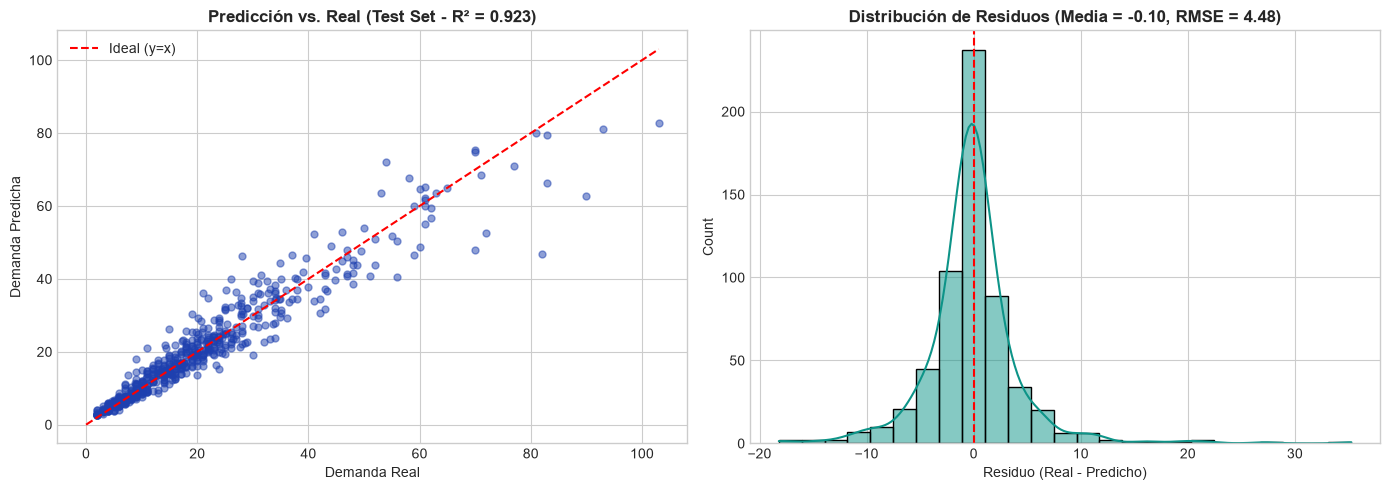

In [12]:
residuos = y_test - y_gb
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(y_test, y_gb, alpha=0.5, color='#1E40AF', s=25)
ax1.plot([0, y_test.max()], [0, y_test.max()], color='red', linestyle='--', label='Ideal (y=x)')
ax1.set_title('Predicción vs. Real (Test Set - R² = 0.923)', fontweight='bold')
ax1.set_xlabel('Demanda Real')
ax1.set_ylabel('Demanda Predicha')
ax1.legend()

sns.histplot(residuos, kde=True, ax=ax2, color='#0D9488', bins=25)
ax2.axvline(0, color='red', linestyle='--')
ax2.set_title(f'Distribución de Residuos (Media = {residuos.mean():.2f}, RMSE = 4.48)', fontweight='bold')
ax2.set_xlabel('Residuo (Real - Predicho)')
plt.tight_layout()
plt.show()

## **8. Exportación del Modelo y Demostración de Inferencia en Vivo (Paso 4 / 6.3)**
Se exporta el pipeline completo en `modelo_demanda_3a.joblib` y se ejecuta una predicción en tiempo real sobre un registro nuevo, calculando el **Stock de Seguridad ($SS$)** y el **Punto de Reorden ($ROP$)** para Tiendas 3A.

In [13]:
# Exportar modelo
joblib.dump(pipe_gb, 'modelo_demanda_3a.joblib')
print('✓ Modelo exportado como modelo_demanda_3a.joblib')

# Registro nuevo: Mandarina en sábado de quincena
nuevo = pd.DataFrame([{
    'precio': 4.5, 'costo': 3.1, 'lag_1d': 18.0, 'lag_7d': 22.0,
    'media_movil_7d': 19.4, 'std_movil_7d': 2.8, 'dia_semana': 5,
    'es_fin_de_semana': 1, 'es_quincena': 1, 'categoria_id': 'fv'
}])

pipe_cargado = joblib.load('modelo_demanda_3a.joblib')
pred_unidades = pipe_cargado.predict(nuevo)[0]
lead_time = 1
z_95 = 1.645
ss = z_95 * 2.8 * np.sqrt(lead_time)
rop = (pred_unidades * (lead_time + 1)) + ss

print(f'\nDemanda Diaria Predicha: {pred_unidades:.2f} kg')
print(f'Stock de Seguridad (SS 95%): {ss:.2f} kg')
print(f'Punto de Reorden (ROP):      {rop:.2f} kg')
print(f'Acción Logística para MVP:   Si Stock <= {rop:.1f} kg -> Emitir orden de compra automática.')

✓ Modelo exportado como modelo_demanda_3a.joblib

Demanda Diaria Predicha: 24.94 kg
Stock de Seguridad (SS 95%): 4.61 kg
Punto de Reorden (ROP):      54.48 kg
Acción Logística para MVP:   Si Stock <= 54.5 kg -> Emitir orden de compra automática.
